# 多項式回帰 — 過学習を自分で起こす

**出典**　機械学習 4 分野の教科書 — 第 2 章 1-A 回帰と正則化 ／ 03 多項式回帰：過学習を自分で起こしてみる

**このノートのパス**　`ml-code/02_regression/02_polynomial_overfit.ipynb`

**このノートで確かめること**
次数 M を上げていくと、**訓練データの 20 点を完璧に通る曲線**ができあがり、
**真の関数から離れていく**ことを目で見る。

| 項目 | 内容 |
|---|---|
| 必要なパッケージ | `scikit-learn, numpy, matplotlib` |
| 実行時間の目安 | 約 10 秒 |
| 前提 | **このノート単体で完結する**（他のノートを先に実行する必要はない） |

In [2]:
# 未導入なら実行する（Colab など）
# !pip install -q scikit-learn numpy matplotlib

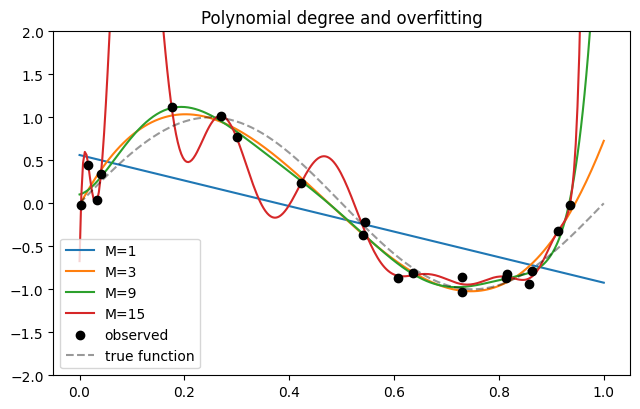

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

rng = np.random.default_rng(0)
X = np.sort(rng.uniform(0, 1, 20))[:, None]
y = np.sin(2 * np.pi * X).ravel() + rng.normal(0, 0.25, 20)   # 真の関数 + ノイズ

xs = np.linspace(0, 1, 300)[:, None]
plt.figure(figsize=(6.5, 4.2))
for M in [1, 3, 9, 15]:
    model = make_pipeline(PolynomialFeatures(M), LinearRegression()).fit(X, y)
    plt.plot(xs, model.predict(xs), label=f"M={M}")
plt.scatter(X, y, c="k", zorder=5, label="observed")
plt.plot(xs, np.sin(2 * np.pi * xs), "k--", alpha=.4, label="true function")
plt.ylim(-2, 2); plt.legend(); plt.title("Polynomial degree and overfitting")
plt.tight_layout(); plt.show()

### 訓練誤差だけを見ていると気づけない

次数を上げるほど**訓練データへの当てはまりは必ず良くなる**。数字で確かめる。

In [4]:
from sklearn.metrics import mean_squared_error

xs_dense = np.linspace(0, 1, 500)[:, None]
y_true   = np.sin(2 * np.pi * xs_dense).ravel()

print(f"{'M':>3} {'訓練RMSE':>10} {'真の関数とのRMSE':>18} {'最大|係数|':>14}")
for M in [1, 3, 9, 15]:
    m = make_pipeline(PolynomialFeatures(M), LinearRegression()).fit(X, y)
    rmse_tr = np.sqrt(mean_squared_error(y, m.predict(X)))
    rmse_tr_true = np.sqrt(mean_squared_error(y_true, m.predict(xs_dense)))
    print(f"{M:>3} {rmse_tr:>10.4f} {rmse_tr_true:>18.4f} "
          f"{np.abs(m[-1].coef_).max():>14.1f}")

  M     訓練RMSE         真の関数とのRMSE         最大|係数|
  1     0.4667             0.4945            1.5
  3     0.1324             0.1726           36.2
  9     0.1146             0.6494        28813.9
 15     0.0473             8.0962  24049342067.6


## 読み取りどころ

**訓練 RMSE は M とともに単調に下がるのに、真の関数との誤差は途中から跳ね上がる。**
そして**係数の絶対値が爆発している**——これが次のノート（正則化）で罰を与える対象になる。

⚠️ 実務では「真の関数」は手に入らない。だから**検証データ**がその代わりを務める。
訓練誤差だけを見て次数やモデルを選ぶと、必ずこの罠に落ちる。